In [1]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import accuracy_score, classification_report

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout

print("Libraries Imported Successfully!")

Libraries Imported Successfully!


In [2]:
from google.colab import files

uploaded = files.upload()

df = pd.read_csv(list(uploaded.keys())[0])

print(df.head())
print("\nDataset Shape:", df.shape)

Saving Crop_recommendation.csv to Crop_recommendation (1).csv
    N   P   K  temperature   humidity        ph    rainfall label
0  90  42  43    20.879744  82.002744  6.502985  202.935536  rice
1  85  58  41    21.770462  80.319644  7.038096  226.655537  rice
2  60  55  44    23.004459  82.320763  7.840207  263.964248  rice
3  74  35  40    26.491096  80.158363  6.980401  242.864034  rice
4  78  42  42    20.130175  81.604873  7.628473  262.717340  rice

Dataset Shape: (2200, 8)


In [3]:
X = df[['N', 'P', 'K', 'temperature',
        'humidity', 'ph', 'rainfall']]

y = df['label']

encoder = LabelEncoder()
y = encoder.fit_transform(y)

scaler = StandardScaler()
X = scaler.fit_transform(X)

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Data Preprocessing Completed!")
print("Training Samples:", len(X_train))
print("Testing Samples:", len(X_test))

Data Preprocessing Completed!
Training Samples: 1760
Testing Samples: 440


In [4]:
ann_model = Sequential([
    Dense(128, activation='relu', input_shape=(7,)),
    Dropout(0.2),

    Dense(64, activation='relu'),
    Dense(32, activation='relu'),

    Dense(len(encoder.classes_), activation='softmax')
])

ann_model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

ann_model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │         1,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 22)             │           726 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 12,086 (47.21 KB)

 Trainable params: 12,086 (47.21 KB)

 Non-trainable params: 0 (0.00 B)

In [5]:
history = ann_model.fit(
    X_train, y_train,
    epochs=50,
    batch_size=32,
    validation_split=0.2,
    verbose=1
)

print("ANN Training Completed!")

Epoch 1/50
44/44 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - accuracy: 0.2230 - loss: 2.8181 - val_accuracy: 0.3295 - val_loss: 2.4293
Epoch 2/50
44/44 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.4503 - loss: 1.9462 - val_accuracy: 0.6875 - val_loss: 1.3151
Epoch 3/50
44/44 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7521 - loss: 1.0024 - val_accuracy: 0.8750 - val_loss: 0.6273
Epoch 4/50
44/44 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8388 - loss: 0.5741 - val_accuracy: 0.9062 - val_loss: 0.3847
Epoch 5/50
44/44 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8913 - loss: 0.3946 - val_accuracy: 0.9148 - val_loss: 0.2855
Epoch 6/50
44/44 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9013 - loss: 0.3209 - val_accuracy: 0.9489 - val_loss: 0.2189
Epoch 7/50
44/44 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9226 - loss: 0.2665 - val_accuracy: 0.9318 - val_loss: 0.1978
Epoch 8/50
44/44 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9254 - loss: 0.2444 - val_accuracy: 0.9545 - val_loss:

In [7]:
loss, accuracy = ann_model.evaluate(X_test, y_test)

print("ANN Model Accuracy:", round(accuracy*100, 2), "%")

y_pred = np.argmax(
    ann_model.predict(X_test),
    axis=1
)

print(classification_report(
    y_test,
    y_pred,
    target_names=encoder.classes_
))

14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.9932 - loss: 0.0210
ANN Model Accuracy: 99.32 %
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step
              precision    recall  f1-score   support

       apple       1.00      1.00      1.00        20
      banana       1.00      1.00      1.00        20
   blackgram       1.00      1.00      1.00        20
    chickpea       1.00      1.00      1.00        20
     coconut       1.00      1.00      1.00        20
      coffee       1.00      1.00      1.00        20
      cotton       0.95      1.00      0.98        20
      grapes       1.00      1.00      1.00        20
        jute       0.95      0.95      0.95        20
 kidneybeans       1.00      1.00      1.00        20
      lentil       1.00      1.00      1.00        20
       maize       1.00      0.95      0.97        20
       mango       1.00      1.00      1.00        20
   mothbeans       1.00      1.00      1.00        20
    mungbean       1.00      1.00      1.00     

In [8]:
# Example soil and weather input
# N, P, K, temperature, humidity, pH, rainfall

new_data = np.array([[90, 42, 43, 25, 80, 6.5, 200]])

new_data = scaler.transform(new_data)

prediction = ann_model.predict(new_data)

crop = encoder.inverse_transform(
    [np.argmax(prediction)]
)

print("Recommended Crop:", crop[0])

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 58ms/step
Recommended Crop: rice


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


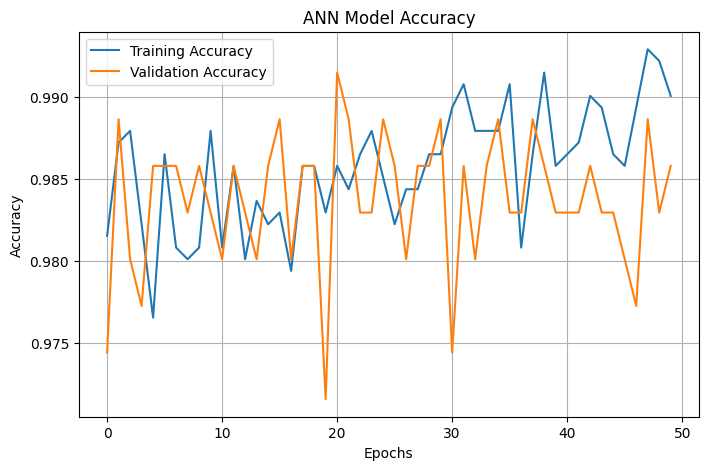

In [9]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))

plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')

plt.title('ANN Model Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.grid()
plt.show()

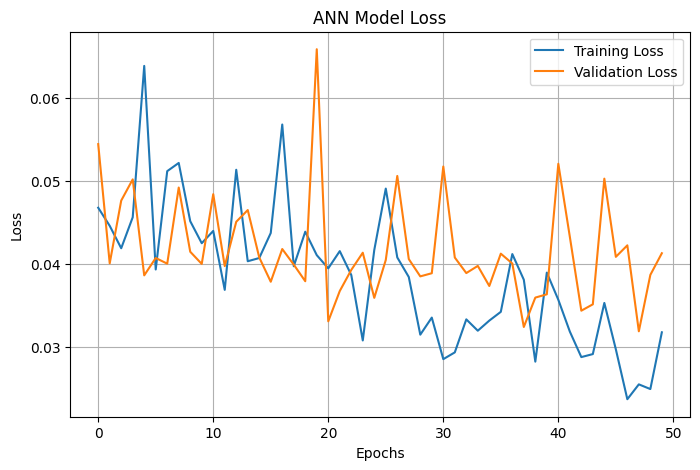

In [10]:
plt.figure(figsize=(8,5))

plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')

plt.title('ANN Model Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid()
plt.show()

In [11]:
results = pd.DataFrame({
    'Actual Crop': encoder.inverse_transform(y_test),
    'Predicted Crop': encoder.inverse_transform(y_pred)
})

print(results.head(20).to_string(index=False))

Actual Crop Predicted Crop
     orange         orange
     banana         banana
     cotton         cotton
      maize          maize
     orange         orange
   chickpea       chickpea
       rice           rice
  blackgram      blackgram
     banana         banana
     orange         orange
 watermelon     watermelon
pomegranate    pomegranate
 watermelon     watermelon
      maize          maize
  mothbeans      mothbeans
     grapes         grapes
     grapes         grapes
      mango          mango
      mango          mango
      apple          apple


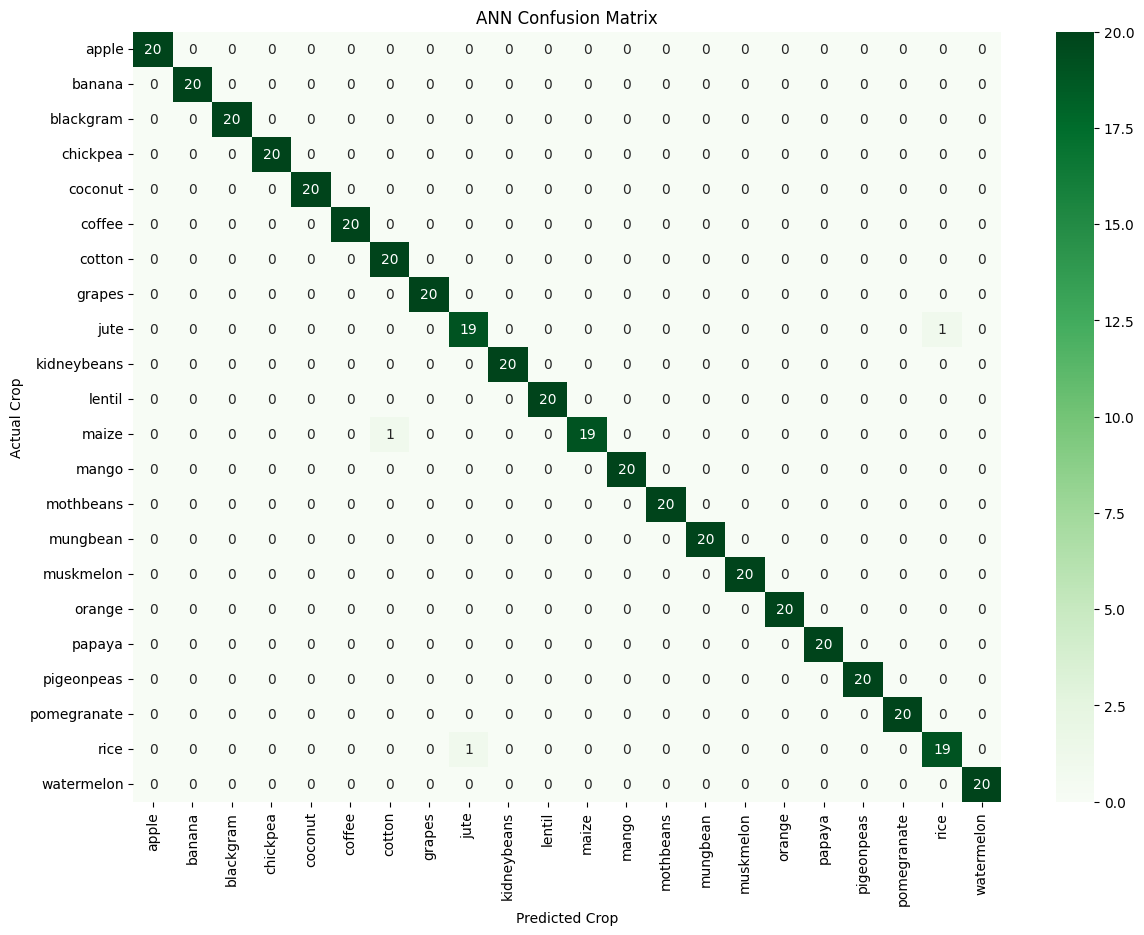

In [12]:
import seaborn as sns
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(14,10))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Greens',
    xticklabels=encoder.classes_,
    yticklabels=encoder.classes_
)

plt.title('ANN Confusion Matrix')
plt.xlabel('Predicted Crop')
plt.ylabel('Actual Crop')
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.show()

In [13]:
from sklearn.metrics import classification_report

report = classification_report(
    y_test,
    y_pred,
    target_names=encoder.classes_,
    output_dict=True
)

report_df = pd.DataFrame(report).transpose()

display(report_df.round(3))

,precision,recall,f1-score,support
apple,1.000,1.000,1.000,20.000
banana,1.000,1.000,1.000,20.000
blackgram,1.000,1.000,1.000,20.000
chickpea,1.000,1.000,1.000,20.000
coconut,1.000,1.000,1.000,20.000
coffee,1.000,1.000,1.000,20.000
cotton,0.952,1.000,0.976,20.000
grapes,1.000,1.000,1.000,20.000
jute,0.950,0.950,0.950,20.000
kidneybeans,1.000,1.000,1.000,20.000


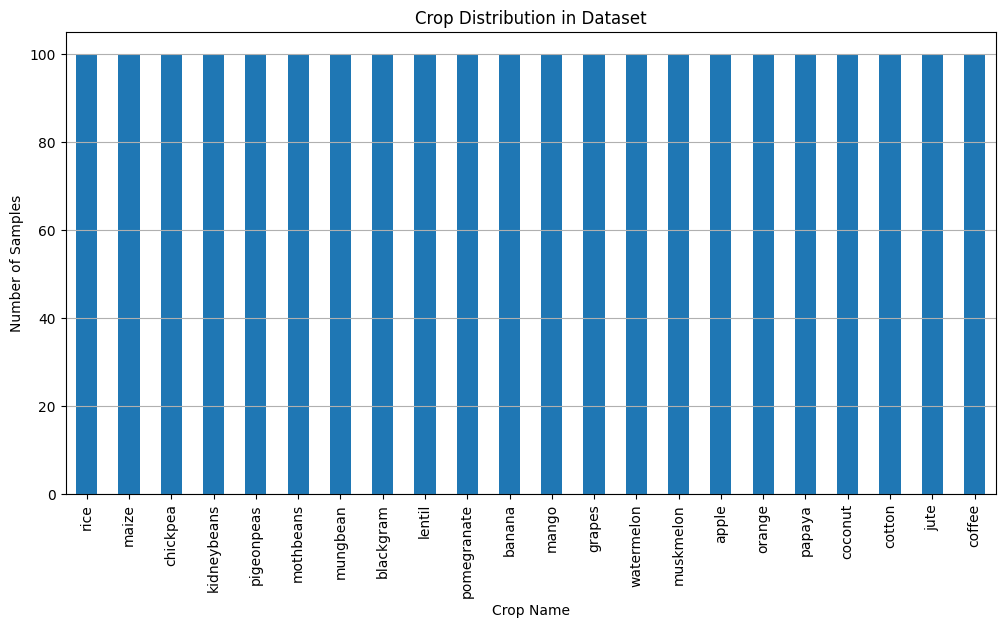

In [14]:
crop_counts = df['label'].value_counts()

plt.figure(figsize=(12,6))

crop_counts.plot(kind='bar')

plt.title('Crop Distribution in Dataset')
plt.xlabel('Crop Name')
plt.ylabel('Number of Samples')
plt.xticks(rotation=90)
plt.grid(axis='y')
plt.show()